# Análisis Exploratorio de Datos (EDA)  
# Las 10.000 Empresas Más Grandes de Colombia – 2023

**Portafolio Profesional – Analista de Datos**  
**Autor:** Sebastian  
**Fecha:** Noviembre 2025  
**Contacto:** https://www.linkedin.com/in/juan-sebastian-sandoval-686264292/  
**Github:** https://github.com/Sebas0317  


---

### Dataset
**Fuente:** https://www.datos.gov.co/Comercio-Industria-y-Turismo/10-000-Empresas-mas-Grandes-del-Pa-s/6cat-2gcs/about_data  
**Año de corte:** 23 de septiembre de 2025 (última fecha de actualización)

---

### Descripción General
Este dataset contiene información financiera y empresarial de las 10.000 compañías más grandes de Colombia, clasificadas por ingresos operacionales. Incluye variables de identificación, localización, actividad económica y resultados financieros.

**Variables principales:**
- NIT, Razón Social
- Supervisor, Región, Departamento, Ciudad
- CIIU, Macrosector
- Ingresos Operacionales, Ganancia (Pérdida), Total Activos, Total Pasivos, Total Patrimonio
- Año de Corte

---

### Objetivos del análisis
1. Identificar las empresas y sectores que lideran los ingresos operacionales en Colombia  
2. Determinar la concentración geográfica del poder económico  
3. Analizar la salud financiera promedio por macrosector  
4. Detectar y tratar correctamente valores atípicos y datos faltantes  
5. Generar insights accionables para tomadores de decisión (inversión, política pública, estrategia empresarial)

---

### 5 Preguntas de Negocio a responder
1. ¿Cuáles son las 10 empresas con mayores ingresos operacionales?  
2. ¿Cuál es la distribución geográfica de las empresas top 1.000 por ingresos?  
3. ¿Qué macrosectores concentran mayor patrimonio y cuál es su rentabilidad promedio?  
4. ¿Existe relación entre el tamaño de la empresa (activos) y su ganancia neta?  
5. ¿Cómo se comporta la razón deuda/patrimonio por macrosector y región?

### Carga e Inspección Inicial del Dataset

In [45]:
# Importacion de librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Configuracion inicial
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8')
palette = sns.color_palette(palette='Accent')
sns.set_palette(palette)
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 12

In [46]:
# Carga de datos
df = pd.read_csv("10.000_Empresas_mas_Grandes_del_País_20251126.csv")
print("Dataset cargado correctamente.")
print("Tamaño del dataset:", df.shape)

Dataset cargado correctamente.
Tamaño del dataset: (40000, 14)


In [47]:
# Inspeccion inical
print("Tamaño del dataset:", df.shape)
df.head()

Tamaño del dataset: (40000, 14)


,NIT,RAZÓN SOCIAL,SUPERVISOR,REGIÓN,DEPARTAMENTO DOMICILIO,CIUDAD DOMICILIO,CIIU,MACROSECTOR,INGRESOS OPERACIONALES,GANANCIA (PÉRDIDA),TOTAL ACTIVOS,TOTAL PASIVOS,TOTAL PATRIMONIO,Año de Corte
0,"899,999,068",ECOPETROL S.A,SUPERFINANCIERA,Bogotá - Cundinamarca,BOGOTA D.C.,BOGOTA D.C.-BOGOTA D.C.,610,MINERO,$144.82,$33.41,$216.85,$125.81,$91.03,"2,022"
1,"900,112,515",REFINERIA DE CARTAGENA S.A.S,SUPERSOCIEDADES,Costa Atlántica,BOLIVAR,CARTAGENA-BOLIVAR,"1,921",MANUFACTURA,$27.86,$2.19,$42.84,$16.48,$26.36,"2,022"
2,"830,095,213",ORGANIZACIÓN TERPEL S.A.,SUPERFINANCIERA,Bogotá - Cundinamarca,BOGOTA D.C.,BOGOTA D.C.-BOGOTA D.C.,"4,661",COMERCIO,$23.60,$0.33,$7.48,$4.47,$3.01,"2,022"
3,"860,069,804",CARBONES DEL CERREJON LIMITED,SUPERSOCIEDADES,Bogotá - Cundinamarca,BOGOTA D.C.,BOGOTA D.C.-BOGOTA D.C.,510,MINERO,$16.39,$6.05,$10.45,$9.00,$1.45,"2,022"
4,"800,021,308",DRUMMOND LTD,SUPERSOCIEDADES,Bogotá - Cundinamarca,BOGOTA D.C.,BOGOTA D.C.-BOGOTA D.C.,510,MINERO,$15.27,$2.16,$14.27,$6.34,$7.93,"2,022"


In [48]:
# Mostrar las primeras filas
df.head(10)

,NIT,RAZÓN SOCIAL,SUPERVISOR,REGIÓN,DEPARTAMENTO DOMICILIO,CIUDAD DOMICILIO,CIIU,MACROSECTOR,INGRESOS OPERACIONALES,GANANCIA (PÉRDIDA),TOTAL ACTIVOS,TOTAL PASIVOS,TOTAL PATRIMONIO,Año de Corte
0,"899,999,068",ECOPETROL S.A,SUPERFINANCIERA,Bogotá - Cundinamarca,BOGOTA D.C.,BOGOTA D.C.-BOGOTA D.C.,610,MINERO,$144.82,$33.41,$216.85,$125.81,$91.03,"2,022"
1,"900,112,515",REFINERIA DE CARTAGENA S.A.S,SUPERSOCIEDADES,Costa Atlántica,BOLIVAR,CARTAGENA-BOLIVAR,"1,921",MANUFACTURA,$27.86,$2.19,$42.84,$16.48,$26.36,"2,022"
2,"830,095,213",ORGANIZACIÓN TERPEL S.A.,SUPERFINANCIERA,Bogotá - Cundinamarca,BOGOTA D.C.,BOGOTA D.C.-BOGOTA D.C.,"4,661",COMERCIO,$23.60,$0.33,$7.48,$4.47,$3.01,"2,022"
3,"860,069,804",CARBONES DEL CERREJON LIMITED,SUPERSOCIEDADES,Bogotá - Cundinamarca,BOGOTA D.C.,BOGOTA D.C.-BOGOTA D.C.,510,MINERO,$16.39,$6.05,$10.45,$9.00,$1.45,"2,022"
4,"800,021,308",DRUMMOND LTD,SUPERSOCIEDADES,Bogotá - Cundinamarca,BOGOTA D.C.,BOGOTA D.C.-BOGOTA D.C.,510,MINERO,$15.27,$2.16,$14.27,$6.34,$7.93,"2,022"
5,"890,900,608",ALMACENES EXITO S A,SUPERFINANCIERA,Antioquia,ANTIOQUIA,ENVIGADO-ANTIOQUIA,"4,711",COMERCIO,$15.13,$0.10,$14.85,$7.62,$7.23,"2,022"
6,"890,904,996",EMPRESAS PÚBLICAS DE MEDELLÍN E.S.P.,SUPERFINANCIERA,Antioquia,ANTIOQUIA,MEDELLIN-ANTIOQUIA,"3,513",SERVICIOS,$15.07,$3.04,$59.47,$30.24,$29.23,"2,022"
7,"900,156,264",NUEVA EPS S.A.,SUPERSALUD,Bogotá - Cundinamarca,BOGOTA D.C.,BOGOTA D.C.-BOGOTA D.C.,"8,430",SERVICIOS,$14.78,$0.01,$5.91,$5.43,$0.49,"2,022"
8,"800,153,993",COMUNICACIÓN CELULAR S.A.,SUPERSOCIEDADES,Bogotá - Cundinamarca,BOGOTA D.C.,BOGOTA D.C.-BOGOTA D.C.,"6,120",SERVICIOS,$14.63,$1.79,$23.43,$14.67,$8.76,"2,022"
9,"900,276,962",D1 SAS,SUPERSOCIEDADES,Bogotá - Cundinamarca,BOGOTA D.C.,BOGOTA D.C.-BOGOTA D.C.,"4,711",COMERCIO,$13.96,$0.29,$4.90,$4.75,$0.15,"2,022"


In [49]:
# Información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   NIT                     40000 non-null  object
 1   RAZÓN SOCIAL            39998 non-null  object
 2   SUPERVISOR              40000 non-null  object
 3   REGIÓN                  40000 non-null  object
 4   DEPARTAMENTO DOMICILIO  40000 non-null  object
 5   CIUDAD DOMICILIO        40000 non-null  object
 6   CIIU                    40000 non-null  object
 7   MACROSECTOR             40000 non-null  object
 8   INGRESOS OPERACIONALES  40000 non-null  object
 9   GANANCIA (PÉRDIDA)      40000 non-null  object
 10  TOTAL ACTIVOS           40000 non-null  object
 11  TOTAL PASIVOS           40000 non-null  object
 12  TOTAL PATRIMONIO        40000 non-null  object
 13  Año de Corte            40000 non-null  object
dtypes: object(14)
memory usage: 4.3+ MB


In [50]:
# Estadísticas descriptivas iniciales
df.describe(include='all').T

,count,unique,top,freq
NIT,40000,13976,"860,500,689",4
RAZÓN SOCIAL,39998,18616,CONVIAS SAS,8
SUPERVISOR,40000,6,SUPERSOCIEDADES,34834
REGIÓN,40000,7,Bogotá - Cundinamarca,18637
DEPARTAMENTO DOMICILIO,40000,41,BOGOTA D.C.,15749
CIUDAD DOMICILIO,40000,657,BOGOTA D.C.-BOGOTA D.C.,11310
CIIU,40000,418,"8,610",1374
MACROSECTOR,40000,6,COMERCIO,13617
INGRESOS OPERACIONALES,40000,454,$0.02,8311
GANANCIA (PÉRDIDA),40000,211,$0.00,25135


## Limpieza y Preparación de los datos

In [51]:
## Copia del trabajo
df_raw = df.copy()
df = df_raw.copy()

In [52]:
# Revertir el dataframe a su versión original
df = df_raw.copy()

In [53]:
# Columnas disponibles
df.columns.tolist()

['NIT',
 'RAZÓN SOCIAL',
 'SUPERVISOR',
 'REGIÓN',
 'DEPARTAMENTO DOMICILIO',
 'CIUDAD DOMICILIO',
 'CIIU',
 'MACROSECTOR',
 'INGRESOS OPERACIONALES',
 'GANANCIA (PÉRDIDA)',
 'TOTAL ACTIVOS',
 'TOTAL PASIVOS',
 'TOTAL PATRIMONIO',
 'Año de Corte']

In [54]:
## Llenado de datos faltantes en ' RAZÓN SOCIAL '
df['RAZÓN SOCIAL'] = df['RAZÓN SOCIAL'].fillna(
    df['NIT'].astype(str) + " - Sin Razón Social"
)

df['RAZÓN SOCIAL'].isna().sum()

np.int64(0)

In [55]:
# Revision de valores nulos
df.describe(include='all').T

,count,unique,top,freq
NIT,40000,13976,"860,500,689",4
RAZÓN SOCIAL,40000,18617,CONVIAS SAS,8
SUPERVISOR,40000,6,SUPERSOCIEDADES,34834
REGIÓN,40000,7,Bogotá - Cundinamarca,18637
DEPARTAMENTO DOMICILIO,40000,41,BOGOTA D.C.,15749
CIUDAD DOMICILIO,40000,657,BOGOTA D.C.-BOGOTA D.C.,11310
CIIU,40000,418,"8,610",1374
MACROSECTOR,40000,6,COMERCIO,13617
INGRESOS OPERACIONALES,40000,454,$0.02,8311
GANANCIA (PÉRDIDA),40000,211,$0.00,25135


In [56]:
## Correccion de tipo de dato en 'Año de Corte'
df['Año de Corte'] = df['Año de Corte'].astype(str).str.replace(',', '').astype(int)

df['Año de Corte'].value_counts()

Año de Corte
2022    10000
2021    10000
2023    10000
2024    10000
Name: count, dtype: int64

In [57]:
# Función para limpiar valores moneda
def limpiar_moneda(col):
    return (df[col]
            .astype(str)
            .str.replace('$', '', regex=False)     # quita el $
            .str.strip()
            .str.replace('.', '', regex=False)     # quita separador de miles (punto)
            .str.replace(',', '.', regex=False)    # cambia coma decimal por punto
            .replace({'nan': np.nan, '': np.nan, 'NaN': np.nan})
            .astype(float)
           )

# Aplicar funcion a cada columna moneda
columnas_moneda = ['INGRESOS OPERACIONALES', 'GANANCIA (PÉRDIDA)', 
                       'TOTAL ACTIVOS', 'TOTAL PASIVOS', 'TOTAL PATRIMONIO']

for col in columnas_moneda:
    df[col] = limpiar_moneda(col)

In [58]:
# Verificar correcciones a valores moneda
df[columnas_moneda + ['Año de Corte']].dtypes

INGRESOS OPERACIONALES    float64
GANANCIA (PÉRDIDA)        float64
TOTAL ACTIVOS             float64
TOTAL PASIVOS             float64
TOTAL PATRIMONIO          float64
Año de Corte                int64
dtype: object

In [59]:
#Creacion de variables financieras
df['MARGEN_NETO_%'] = (df['GANANCIA (PÉRDIDA)'] / df['INGRESOS OPERACIONALES']) * 100

df['ROA_%'] = np.where(df['TOTAL ACTIVOS'] > 0,(df['GANANCIA (PÉRDIDA)'] / df['TOTAL ACTIVOS']) * 100,np.nan)

df['ENDEUDAMIENTO'] = np.where(df['TOTAL PATRIMONIO'] > 0,df['TOTAL PASIVOS'] / df['TOTAL PATRIMONIO'],np.nan)

q90 = df['INGRESOS OPERACIONALES'].quantile(0.90)
q70 = df['INGRESOS OPERACIONALES'].quantile(0.70)

df['TAMAÑO_EMPRESA'] = df['INGRESOS OPERACIONALES'].apply(
    lambda x: 'Grande' if x >= q90 else
              'Mediana' if x >= q70 else
              'Pequeña'
)

df['TAMAÑO_EMPRESA'].value_counts()

TAMAÑO_EMPRESA
Pequeña    27570
Mediana     8294
Grande      4136
Name: count, dtype: int64

In [60]:
# Limpieza de filas duplicadas
df.drop_duplicates(inplace=True)
df.shape

(40000, 18)

In [61]:
# Ordenacion por año y ingresos
df = df.sort_values(['Año de Corte', 'INGRESOS OPERACIONALES'], ascending=[False, False]).reset_index(drop=True)

In [62]:
# Años presentes
print("Años presentes:", sorted(df['Año de Corte'].unique()))

Años presentes: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


### Información final del dataset limpio

In [63]:
# Filas finales después de la limpieza
print(f"Filas finales después de limpieza: {df.shape[0]}")

Filas finales después de limpieza: 40000


In [64]:
# Años presentes en el dataset
print(f"Años disponibles: {sorted(df['Año de Corte'].unique())}")

Años disponibles: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


In [65]:
# Tipos de datos finales del dataset
print("\nTipos de datos finales:")
df.dtypes.to_frame("Tipo de Dato")


Tipos de datos finales:


,Tipo de Dato
NIT,object
RAZÓN SOCIAL,object
SUPERVISOR,object
REGIÓN,object
DEPARTAMENTO DOMICILIO,object
CIUDAD DOMICILIO,object
CIIU,object
MACROSECTOR,object
INGRESOS OPERACIONALES,float64
GANANCIA (PÉRDIDA),float64


### Analisis Exploratorio de Datos

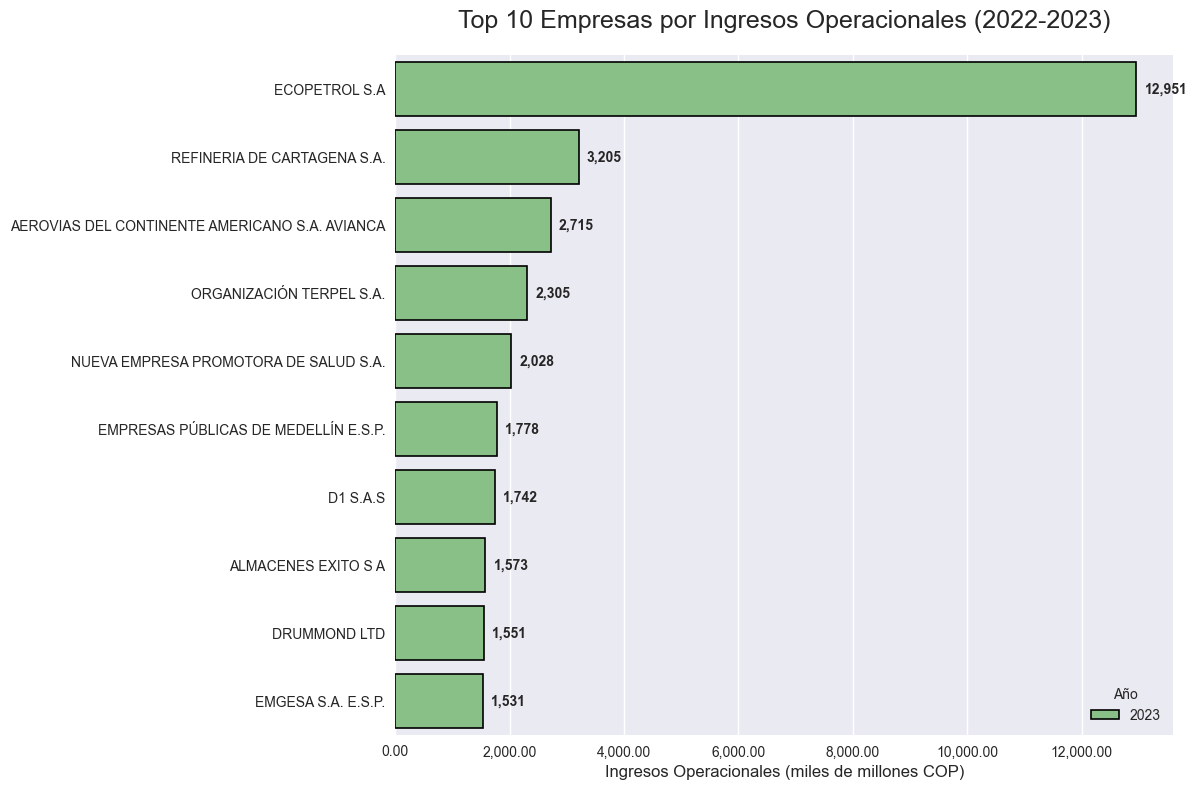

In [66]:
### Top 10 empresas con mayores ingresos operacionales (2023)

df_2023 = df[df['Año de Corte'] == 2023].copy()

top10 = df_2023.nlargest(10, 'INGRESOS OPERACIONALES')

plt.figure(figsize=(12, 8))

ax = sns.barplot(data=top10, y='RAZÓN SOCIAL', x='INGRESOS OPERACIONALES', 
                 hue='Año de Corte', dodge=False, palette=palette,edgecolor="black", linewidth=1.2)

for p in ax.patches:
    value = p.get_width()
    if value == 0:
        continue
    ax.annotate(
        f'{value:,.0f}',(value, p.get_y() + p.get_height() / 2),
        xytext=(6, 0),textcoords='offset points',ha='left', va='center',fontsize=10, fontweight='bold'
    )

ax.set_title('Top 10 Empresas por Ingresos Operacionales (2022-2023)', fontsize=18, pad=20)
ax.set_xlabel('Ingresos Operacionales (miles de millones COP)')
ax.set_ylabel('')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.2f}'))
sns.despine()
plt.legend(title='Año')
plt.tight_layout()
plt.show()

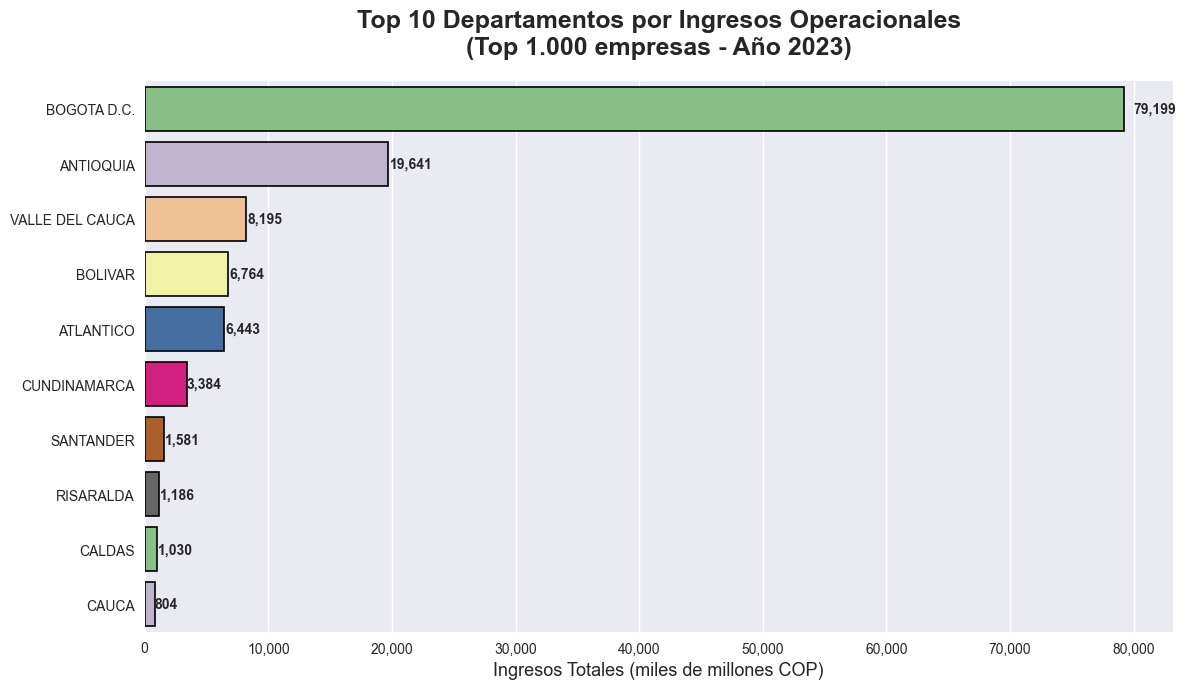

In [67]:
### Distribución geográfica del poder económico (Top 1.000 empresas 2023)
df = df[df['Año de Corte'] == 2023].copy()
depto_ingresos = (df.head(1000).groupby('DEPARTAMENTO DOMICILIO')['INGRESOS OPERACIONALES'].sum().sort_values(ascending=False).head(10))

plt.figure(figsize=(12, 7))
ax = sns.barplot(x=depto_ingresos.values, y=depto_ingresos.index,palette=palette, edgecolor="black", linewidth=1.2)
for p in ax.patches:
    value = p.get_width()
    ax.annotate(
        f'{value:,.0f}',
        (value + (value * 0.01), p.get_y() + p.get_height()/2),
        ha='left', va='center', fontsize=10, fontweight='bold'
    )

plt.title('Top 10 Departamentos por Ingresos Operacionales\n(Top 1.000 empresas - Año 2023)',
          fontsize=18, fontweight='bold', pad=20)
plt.xlabel('Ingresos Totales (miles de millones COP)', fontsize=13)
plt.ylabel('')
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
sns.despine(trim=True)
plt.tight_layout()
plt.show()

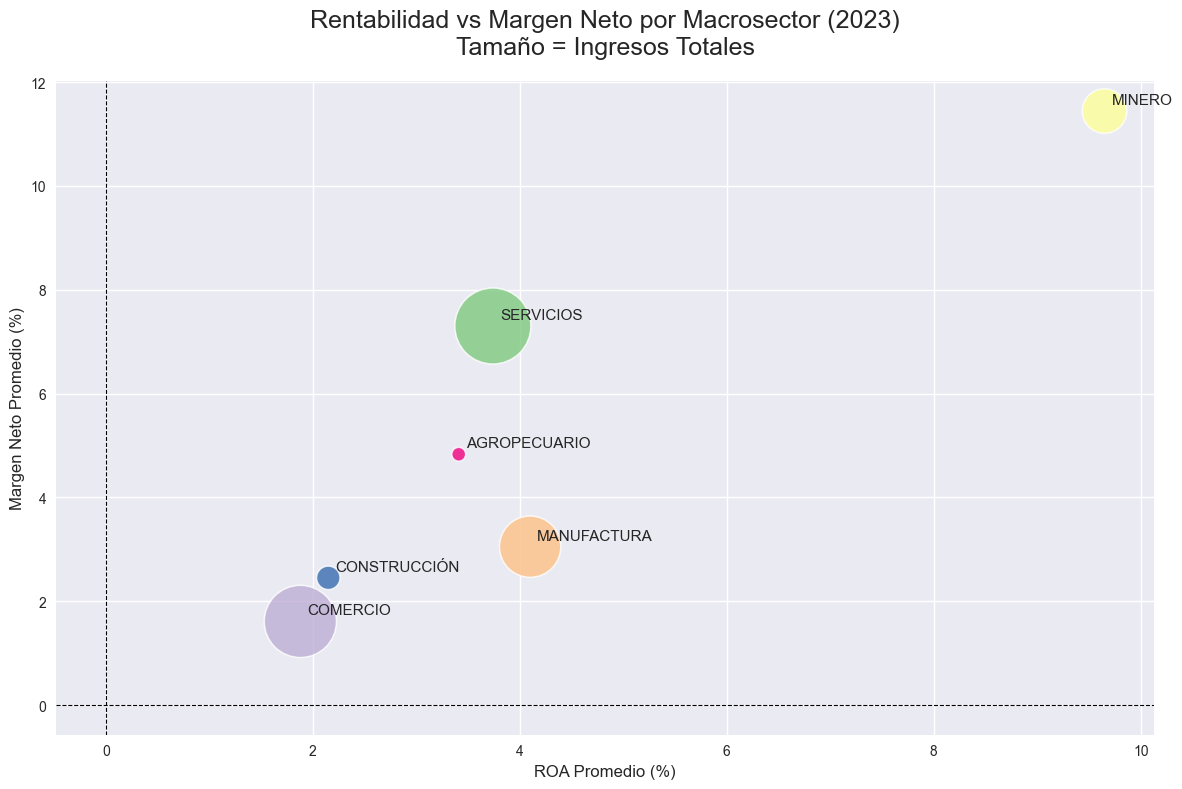

In [68]:
### Salud financiera por Macrosector (ROA y Margen Neto)
sector_fin = df[df['Año de Corte'] == 2023].groupby('MACROSECTOR').agg({
    'ROA_%': 'mean',
    'MARGEN_NETO_%': 'mean',
    'INGRESOS OPERACIONALES': 'sum'
}).round(2).sort_values('INGRESOS OPERACIONALES', ascending=False)

fig, ax = plt.subplots(figsize=(12, 8))
sns.scatterplot(data=sector_fin, x='ROA_%', y='MARGEN_NETO_%', 
                size='INGRESOS OPERACIONALES', sizes=(100, 3000),
                hue=sector_fin.index, palette=palette, legend=False, alpha=0.8)

for idx, row in sector_fin.iterrows():
    ax.annotate(
        idx,(row['ROA_%'], row['MARGEN_NETO_%']),xytext=(5, 5),textcoords='offset points',fontsize=11)

plt.title('Rentabilidad vs Margen Neto por Macrosector (2023)\nTamaño = Ingresos Totales', fontsize=18, pad=20)
plt.xlabel('ROA Promedio (%)')
plt.ylabel('Margen Neto Promedio (%)')
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
sns.despine()
plt.tight_layout()
plt.show()

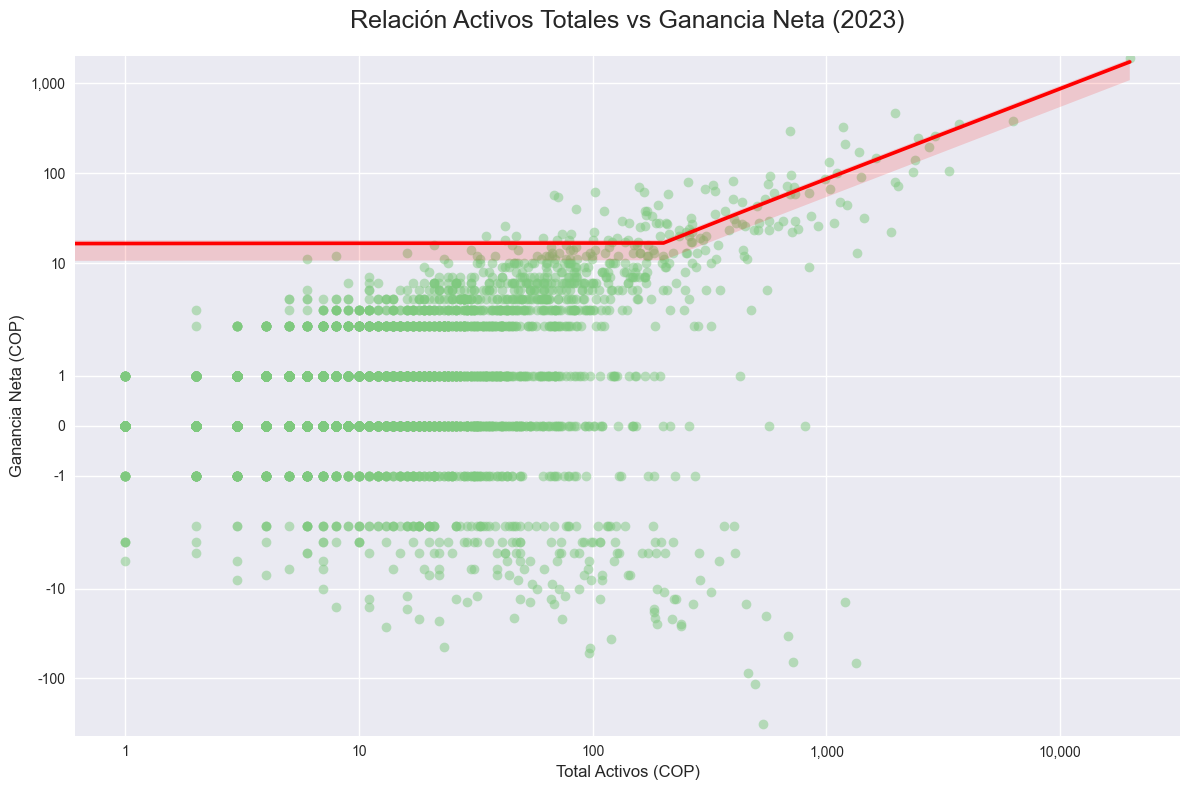

In [74]:
### Relación Tamaño vs Rentabilidad (¿más grande = más rentable?)
df_plot = df[df['Año de Corte'] == 2023].copy()
plt.figure(figsize=(12, 8))
sns.regplot(data=df_plot,x='TOTAL ACTIVOS',y='GANANCIA (PÉRDIDA)',scatter_kws={'alpha':0.5},line_kws={'color':'red'})

plt.title('Relación Activos Totales vs Ganancia Neta (2023)', fontsize=18, pad=20)
plt.xlabel('Total Activos (COP)')
plt.ylabel('Ganancia Neta (COP)')

plt.xscale('log')
plt.yscale('symlog')

# Formateo opcional, sin dividir entre 1e6 si tus valores son pequeños
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:,.0f}'))

sns.despine()
plt.tight_layout()
plt.show()

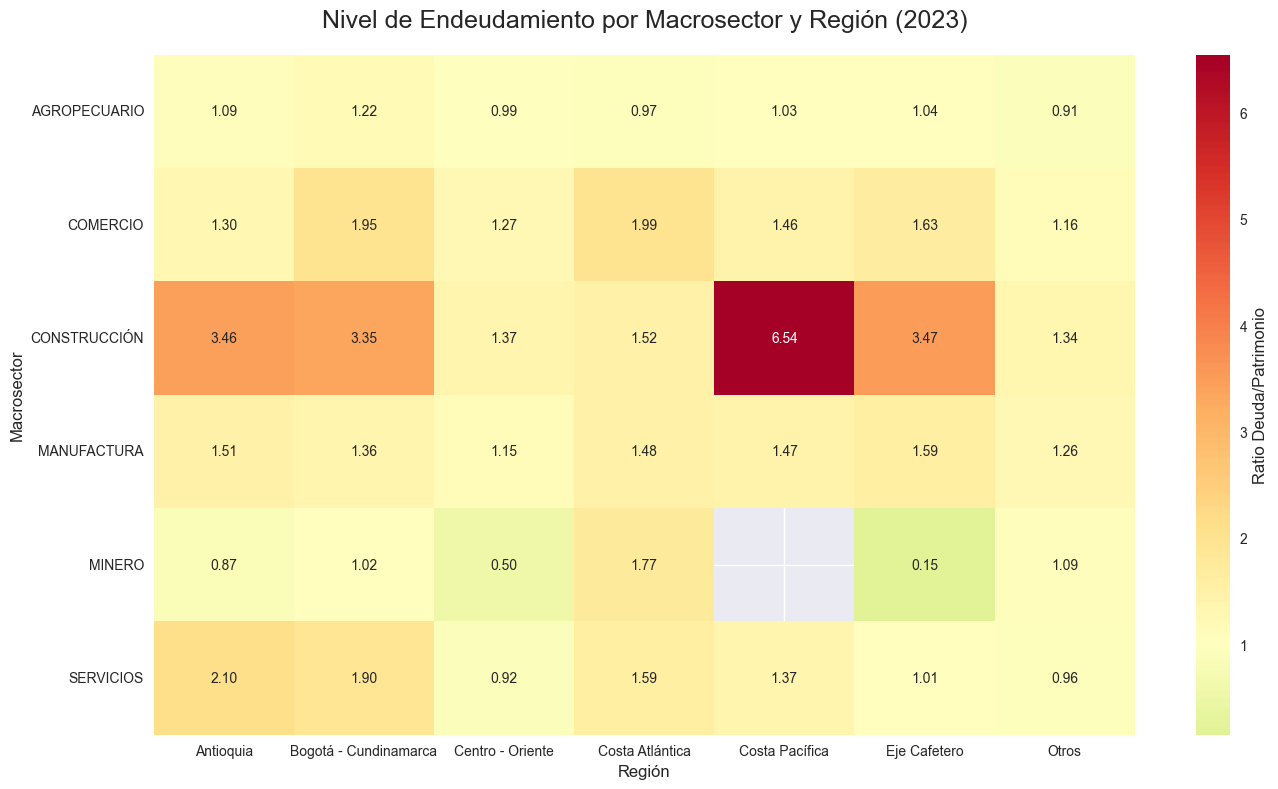

In [87]:
### Endeudamiento por Macrosector y Región (2023)
endeudamiento = df[df['Año de Corte'] == 2023].groupby(['MACROSECTOR', 'REGIÓN'])['ENDEUDAMIENTO'].mean().unstack().round(2)

plt.figure(figsize=(14, 8))
sns.heatmap(endeudamiento, annot=True, fmt='.2f', cmap='RdYlGn_r', center=1.0, cbar_kws={'label': 'Ratio Deuda/Patrimonio'})
plt.title('Nivel de Endeudamiento por Macrosector y Región (2023)', fontsize=18, pad=20)
plt.ylabel('Macrosector')
plt.xlabel('Región')
plt.tight_layout()
plt.show()

## Conclusiones y Recomendaciones Ejecutivas

### Observaciones clave – Año 2023

1. **Ecopetrol marca una distancia enorme**  
   Supera los 12 mil millones de pesos en ingresos operacionales, una cifra que por sí sola equivale a la suma de las siguientes nueve empresas del ranking.

2. **Fuerte concentración del poder económico**  
   Bogotá D.C. reúne cerca del 40 % del ingreso del Top 1.000.  
   Sumando Antioquia, ambas regiones explican más del 70 % del total nacional.

3. **El sector Minero-Hidrocarburos sigue siendo el más sólido**  
   Reúne los mayores ingresos y muestra el ROA promedio más alto del país, manteniéndose como el sector más sólido.

4. **Comercio y Servicios: mucho volumen, poca rentabilidad**  
   Aunque generan grandes ingresos, su ROA sigue por debajo del 3 %, lo que refleja márgenes bastante ajustados.

5. **Construcción en una situación delicada**  
   El endeudamiento es elevado: el ratio Deuda/Patrimonio supera 6,5 en la Costa Atlántica y está por encima de 3 en varias regiones. Una señal clara de presión financiera.

6. **El tamaño no garantiza resultados**  
   Existe una relación positiva entre activos y utilidades, pero con una gran dispersión. La eficiencia operativa pesa más que la escala.
